# Simple Momentum Strategy vs. Buy & Hold

## Summary

| | |
| :--- | :--- |
| **Idea** | A price rise of P% over D1 days on above-average volume predicts further gains over the next D2 days. |
| **Verdict** | Inconclusive, leaning rejected |
| **Result** | 2,534 trades on 34 tickers: 49% win rate, +0.49% average per trade, median worst drawdown per trade -5.8%. Best grid cell (D1=5, P=20%, D2=10) averaged +1.6% per trade with a 41% win rate. |
| **Trust** | Low. The compounded return came out at 10^30, exposing a compounding bug; the most profitable trade was a penny stock (MARK, +276%); 17 of 53 tickers had zero volume on a normal trading day; no trading costs. |
| **Date** | 2026-08-29 |
| **Code status** | Frozen: written before the current modules and no longer runs. Read it as a report. |

*Summary added 2026-10-13 by Claude from this notebook's own commentary and stored results. The verdict is a draft for Ben to confirm or correct.*

# Simple Momentum Strategy vs. Buy & Hold

**Hypothesis**: Price and Volume increase over $D1$ days ($P1\%$) predicts continuation for $D2$ days.
**Universe**: [watchlist.csv](watchlist.csv) (excluding `DELISTED` and `INVALID` tickers from `mt-tickers.csv`).
**Benchmark**: Equally weighted Buy & Hold of the same universe.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Set plotting style
plt.style.use('ggplot')

## 1. Data Ingestion & Filtering
We filter out `DELISTED` and `INVALID` tickers confirmed by our fundamentals engine to ensure we only trade "real" companies.


In [7]:
# 1. Load Watchlist
wl_df = pd.read_csv('watchlist.csv')
watchlist = wl_df['ticker'].astype(str).str.strip().str.upper().tolist()
watchlist = [t for t in watchlist if not t.startswith('#')]

# 2. Advanced Filtering using mt-tickers (Fundamentals + Status)
mt_tickers = pd.read_csv('MT/mt-tickers.csv')

# --- PRE-FILTERING CRITERIA ---
# a) Exclude definitely broken tickers — DELISTED (confirmed gone) and INVALID (no MT data)
invalid_tickers = mt_tickers[mt_tickers['status'].isin(['DELISTED', 'INVALID'])]['ticker'].tolist()

# b) Flexible filtering
# We want to exclude stocks that are definitively marked DELISTED or INVALID.
# For others, we'll exclude obvious outliers (e.g., negative Price/Book or Price/Sales)
# But we won't be too strict on 'HEALTHY' status yet, in case many are just 'INCOMPLETE'.
unfiltered_tickers = mt_tickers[
    (~mt_tickers['status'].isin(['DELISTED', 'INVALID'])) &
    (mt_tickers['price_book'] != 0) # Basic check to ensure some data exists
]['ticker'].tolist()

universe = [t for t in watchlist if t in unfiltered_tickers and t not in invalid_tickers]

print(f"Watchlist Size: {len(watchlist)}")
print(f"Excluded (DELISTED, INVALID, or No Data): {len(watchlist) - len(universe)}")
print(f"Final Universe Size: {len(universe)}")

# 3. Load YF Pricing Data
yf_df = pd.read_csv('YF/yf-prices.csv')
yf_df['date'] = pd.to_datetime(yf_df['date'])
yf_df = yf_df[yf_df['ticker'].isin(universe)]

# Pivot to Wide-Format
prices = yf_df.pivot(index='date', columns='ticker', values='adj_close').sort_index()
volume = yf_df.pivot(index='date', columns='ticker', values='volume').sort_index().fillna(0)

# --- THE ZERO-TRUST FIX: LIFECYCLE MASKING ---
has_started = (volume > 0).cumsum() > 0
prices = prices.where(has_started)
prices = prices.ffill()

print("\nLifecycle Masking Applied: 'Pre-IPO' artifacts removed.")
display(prices.tail())


Watchlist Size: 58
Excluded (DELISTED, INVALID, or No Data): 24
Final Universe Size: 34

Lifecycle Masking Applied: 'Pre-IPO' artifacts removed.


ticker,AI,ANY,ASNS,BZUN,CDW,CHKP,CLPS,CRNC,CSGP,DAVA,...,S,SAIC,STEM,TASK,TBLA,TLS,TSYHY,UIS,UPST,VRT
date,,,,,,,,,,,,,,,,,,,,,
2026-08-24,10.11,2.43,0.043,2.82,131.879990,130.500000,1.06,7.57,32.840000,3.18,...,20.820000,126.849998,5.46,7.83,3.65,4.38,10.6400,2.63,29.889999,254.970001
2026-08-25,9.79,2.51,0.043,2.83,142.089996,129.520004,1.07,8.02,32.810001,3.25,...,20.309999,127.279999,5.61,7.96,3.70,4.37,11.4608,2.69,30.580000,255.750000
2026-08-26,9.70,2.41,0.043,2.82,141.460007,129.050003,1.07,8.03,32.139999,3.22,...,20.510000,127.580002,5.66,7.75,3.73,4.44,11.4900,2.61,30.469999,263.809998
2026-08-27,10.33,2.56,0.043,3.02,148.970001,133.229996,1.07,8.41,31.340000,3.29,...,22.709999,128.960007,5.70,8.21,3.77,4.82,11.6500,2.72,30.459999,269.279999
2026-08-28,10.53,2.20,0.043,3.02,147.690002,138.320007,1.08,8.50,32.220001,3.21,...,21.540001,125.959999,5.44,8.39,3.78,4.79,11.6600,2.69,29.080000,257.079987


## 2. Momentum Strategy Engine
We define a vectorized trade simulator.
- **Signal**: $D1$ return $\ge P1\%$ AND Volume $>$ SMA(Volume, $D1$).
- **Holding**: Fixed $D2$ days.
- **State**: No overlapping entries (one trade per ticker at a time).

In [8]:
def simulate_momentum(prices, volume, D1=20, P1=0.05, D2=10):
	# Calculate Technicals
	returns_d1 = prices.pct_change(D1)
	vol_sma = volume.rolling(D1).mean()
	
	# Initial Signal Mask
	signals = (returns_d1 >= P1) & (volume > vol_sma)
	
	# Result tracking
	all_trades = []
	
	# Track status for each ticker
	for ticker in prices.columns:
		p_series = prices[ticker]
		s_series = signals[ticker]
		
		in_trade = False
		cooldown = 0
		entry_price = 0
		entry_date = None
		
		# Iterate through time for this ticker (Stateful check)
		for date, is_triggered in s_series.items():
			if cooldown > 0:
				cooldown -= 1
				if cooldown == 0:
					# EXIT
					exit_price = p_series[date]
					all_trades.append({
						'ticker': ticker,
						'entry_date': entry_date,
						'exit_date': date,
						'return': (exit_price / entry_price) - 1,
						'max_drawdown': ((p_series[entry_date:date] / entry_price).min() - 1)
					})
					in_trade = False
				continue
				
			if is_triggered and not in_trade:
				# ENTRY
				in_trade = True
				entry_price = p_series[date]
				entry_date = date
				cooldown = D2
				
	return pd.DataFrame(all_trades)

# Test with a single pair
trades = simulate_momentum(prices, volume, D1=10, P1=0.05, D2=20)
print(f"Total Trades Generated: {len(trades)}")
display(trades.head())

Total Trades Generated: 2534


,ticker,entry_date,exit_date,return,max_drawdown
0,AI,2020-12-23,2021-01-25,-0.082143,-0.295915
1,AI,2021-01-27,2021-02-25,-0.233282,-0.233282
2,AI,2021-04-14,2021-05-12,-0.246421,-0.246421
3,AI,2021-05-21,2021-06-21,-0.053776,-0.064237
4,AI,2021-06-24,2021-07-23,-0.170006,-0.181642


## 3. Backtest vs Benchmark (Buy &amp; Hold)
We compare the performance of this strategy against holding the entire universe.

In [9]:
def backtest_summary(trades, prices):
	# Benchmark: Daily mean return of all tickers (Equal Weighted)
	bh_returns = prices.pct_change().mean(axis=1)
	bh_cum = (1 + bh_returns).cumprod()
	
	# Strategy: Sum returns of all completed trades
	strat_win_rate = (trades['return'] > 0).mean()
	strat_avg_ret = trades['return'].mean()
	strat_med_mdd = trades['max_drawdown'].median()
	
	print("--- STRATEGY STATS ---")
	print(f"Win Rate: {strat_win_rate:.2%}")
	print(f"Avg Return per Trade: {strat_avg_ret:.2%}")
	print(f"Median Max Drawdown: {strat_med_mdd:.2%}")
	print(f"Total Trades: {len(trades)}")
	
	return bh_cum

bh_cum = backtest_summary(trades, prices)

--- STRATEGY STATS ---
Win Rate: 49.13%
Avg Return per Trade: 0.49%
Median Max Drawdown: -5.80%
Total Trades: 2534


## 4. Parameter Grid Search
We search through $(D1, P1, D2)$ combinations to find the "Sweet Spot".
- $D1$: Lookback period for momentum.
- $P1$: Performance threshold for signal.
- $D2$: Holding period.


In [10]:
import itertools

def grid_search(prices, volume, d1_range, p1_range, d2_range):
	results = []
	
	total = len(d1_range) * len(p1_range) * len(d2_range)
	count = 0
	
	for d1, p1, d2 in itertools.product(d1_range, p1_range, d2_range):
		count += 1
		if count % 10 == 0:
			print(f"Progress: {count}/{total}")
			
		trades = simulate_momentum(prices, volume, D1=d1, P1=p1, D2=d2)
		
		if len(trades) > 0:
			win_rate = (trades['return'] > 0).mean()
			avg_ret = trades['return'].mean()
			med_mdd = trades['max_drawdown'].median()
			results.append({
				'D1': d1, 'P1': p1, 'D2': d2,
				'WinRate': win_rate,
				'AvgReturn': avg_ret,
				'MedMDD': med_mdd,
				'Trades': len(trades)
			})
			
	return pd.DataFrame(results)

# Define Search Space
d1_opts = [5, 10, 20, 60]
p1_opts = [0.02, 0.05, 0.10, 0.15]
d2_opts = [5, 10, 20]

gs_df = grid_search(prices, volume, d1_opts, p1_opts, d2_opts)
display(gs_df.sort_values('AvgReturn', ascending=False).head(10))

Progress: 10/48
Progress: 20/48
Progress: 30/48
Progress: 40/48


,D1,P1,D2,WinRate,AvgReturn,MedMDD,Trades
35,20,0.15,20,0.489899,0.009128,-0.078638,990
32,20,0.10,20,0.497386,0.007989,-0.062750,1530
26,20,0.02,20,0.515088,0.007972,-0.049180,2850
38,60,0.02,20,0.521302,0.006141,-0.046086,2488
20,10,0.10,20,0.477941,0.006105,-0.078204,1496
29,20,0.05,20,0.506638,0.005706,-0.051799,2335
34,20,0.15,10,0.482811,0.004921,-0.049488,1309
17,10,0.05,20,0.491318,0.004901,-0.058020,2534
41,60,0.05,20,0.514686,0.004751,-0.046563,2213
14,10,0.02,20,0.506581,0.004686,-0.052705,3267


## 5. Visualizing the "Sweet Spot"
We use a heatmap to identify the best (D1, P1) for a fixed D2.


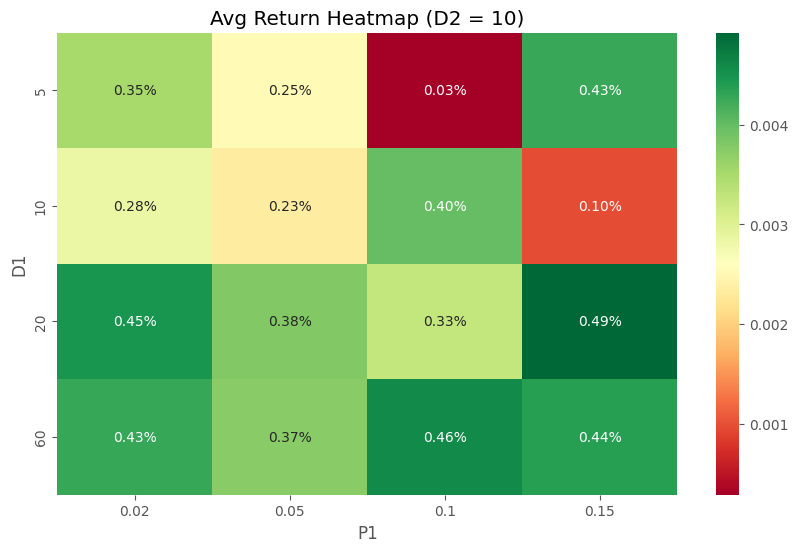

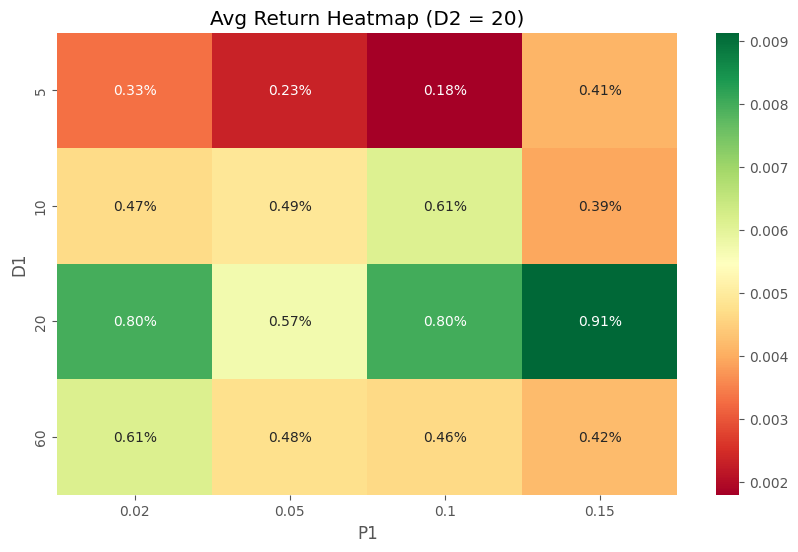

In [11]:
import seaborn as sns

def plot_heatmap(df, d2_val):
	subset = df[df['D2'] == d2_val]
	pivot = subset.pivot(index='D1', columns='P1', values='AvgReturn')
	
	plt.figure(figsize=(10, 6))
	sns.heatmap(pivot, annot=True, fmt=".2%", cmap='RdYlGn')
	plt.title(f"Avg Return Heatmap (D2 = {d2_val})")
	plt.show()

# Plot check for D2=10 and D2=20
plot_heatmap(gs_df, 10)
plot_heatmap(gs_df, 20)

## 6. Equity Curve vs. Benchmark
We calculate the daily performance by aggregating returns of all active signals and comparing to an equally weighted Buy & Hold of the entire universe.


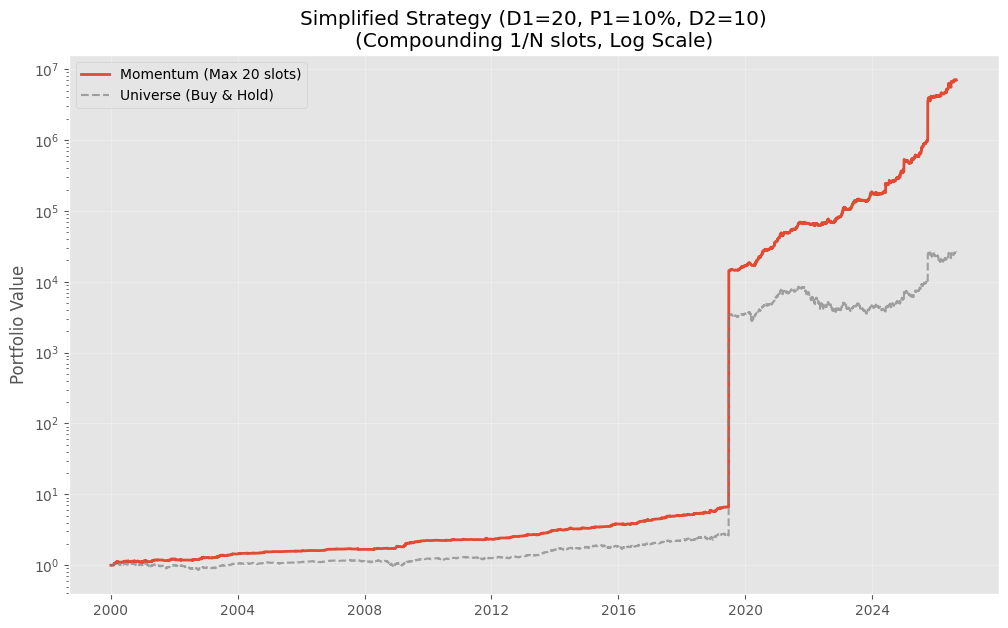

In [12]:
def plot_equity_curve(trades, prices, title="Portfolio Performance", max_slots=20):
    """
    Plots performance assuming we split capital across 'max_slots'.
    If we have 2 active trades, we are 2/20 invested.
    This prevents single-trade volatility from exploding the compounding.
    """
    ticker_daily_ret = prices.pct_change().fillna(0)
    
    active_mask = pd.DataFrame(0, index=prices.index, columns=prices.columns)
    for _, row in trades.iterrows():
        active_mask.loc[row['entry_date']:row['exit_date'], row['ticker']] = 1
    
    # Calculate Strategy Daily Returns using fixed denominator
    # (ticker_daily_ret * active_mask).sum(axis=1) is the total return of current positions
    # We divide by max_slots to assume each position takes 1/max_slots of our bankroll
    strat_daily_ret = (ticker_daily_ret * active_mask).sum(axis=1) / max_slots
    
    # Benchmark (Universe) - also needs to be comparable
    bh_daily_ret = ticker_daily_ret.mean(axis=1)
    
    strat_cum = (1 + strat_daily_ret).cumprod()
    bh_cum = (1 + bh_daily_ret).cumprod()
    
    plt.figure(figsize=(12, 7))
    plt.plot(strat_cum.index, strat_cum, label=f'Momentum (Max {max_slots} slots)', linewidth=2)
    plt.plot(bh_cum.index, bh_cum, label='Universe (Buy & Hold)', linestyle='--', color='gray', alpha=0.7)
    
    plt.yscale('log')
    plt.title(f"{title}\n(Compounding 1/N slots, Log Scale)")
    plt.ylabel('Portfolio Value')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# Test with simplified params and 20 slots
test_trades = simulate_momentum(prices, volume, D1=20, P1=0.10, D2=10)
plot_equity_curve(test_trades, prices, "Simplified Strategy (D1=20, P1=10%, D2=10)", max_slots=20)


In [13]:
# 11. Global Ledger Backtest (The "Dry Powder" Model + Regime Filter + Liquidity Guardrail)
def run_ledger_backtest(prices, volume, market_regime=None, D1=60, P1=0.20, D2=40, max_slots=20, initial_capital=100000, min_dollar_volume=1000000):
    """
    Simulates a real trading account day-by-day.
    - D1: 60 Day Lookback (Quarterly Momentum)
    - P1: 20% Alpha Threshold (High Conviction)
    - D2: 40 Day Holding (Longer Trend Capture)
    """
    # Technicals
    returns_d1 = prices.pct_change(D1)
    vol_sma = volume.rolling(D1).mean()
    
    # 1. Price/Volume Signal
    # We look for a 20% move over 60 days with volume support
    signals_base = (returns_d1 >= P1) & (volume > vol_sma)
    
    # 2. Liquidity Guardrail
    dollar_vol = prices * vol_sma
    liquidity_mask = dollar_vol >= min_dollar_volume
    
    signals = signals_base & liquidity_mask
    
    cash = initial_capital
    slot_size = initial_capital / max_slots
    active_trades = []
    
    history = []
    executed_trades = []

    for date in prices.index[D1:]:
        can_open_new = True if market_regime is None else (market_regime.loc[date] == 1)

        # 1. LIQUIDATE EXPIRED TRADES
        still_active = []
        for trade in active_trades:
            if date >= trade['exit_date']:
                exit_price = prices.at[date, trade['ticker']]
                proceeds = trade['shares'] * exit_price
                cash += proceeds
                executed_trades.append({
                    'ticker': trade['ticker'],
                    'entry_date': trade['entry_date'],
                    'exit_date': date,
                    'return': (exit_price / trade['entry_price']) - 1
                })
            else:
                still_active.append(trade)
        active_trades = still_active

        # 2. CHECK NEW SIGNALS
        if can_open_new:
            todays_signals = signals.loc[date]
            potential_tickers = todays_signals[todays_signals].index.tolist()
            
            for ticker in potential_tickers:
                if len(active_trades) < max_slots and cash >= slot_size:
                    if any(t['ticker'] == ticker for t in active_trades):
                        continue
                    
                    entry_price = prices.at[date, ticker]
                    if not pd.isna(entry_price) and entry_price > 0:
                        shares = slot_size / entry_price
                        cash -= slot_size
                        
                        current_idx = prices.index.get_loc(date)
                        exit_idx = min(current_idx + D2, len(prices.index) - 1)
                        exit_date = prices.index[exit_idx]
                        
                        active_trades.append({
                            'ticker': ticker,
                            'entry_price': entry_price,
                            'entry_date': date,
                            'exit_date': exit_date,
                            'shares': shares
                        })

        # 3. TRACK NAV
        current_holdings_value = sum(trade['shares'] * prices.at[date, trade['ticker']] for trade in active_trades)
        history.append({
            'date': date,
            'cash': cash,
            'holdings_val': current_holdings_value,
            'total_nav': cash + current_holdings_value,
            'active_slots': len(active_trades),
            'regime_mode': 1 if can_open_new else 0
        })

    return pd.DataFrame(history), pd.DataFrame(executed_trades)

# Run simulations with LONGER-TERM Parameters
# D1=60, P1=20%, D2=40
ledger_hist_regime, ledger_trades_regime = run_ledger_backtest(
    prices, volume, market_regime=market_regime, D1=60, P1=0.20, D2=40, max_slots=20, min_dollar_volume=1000000
)

# Visualize Comparison
plt.figure(figsize=(14, 7))
plt.plot(ledger_hist_regime['date'], ledger_hist_regime['total_nav'], label='Momentum (60d Lookback, 40d Hold)', linewidth=2.5)
plt.plot(spy_c.index, (spy_c / spy_c.loc[ledger_hist_regime['date'].min()]) * 100000, 
         label='SPY (Normalized)', color='gray', linestyle='--')

plt.title("Longer-Term Conviction Momentum Strategy\n(60d Lookback, 20% Threshold, 40d Holding)")
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print(f"Final Account Value: ${ledger_hist_regime.iloc[-1]['total_nav']:,.2f}")
print(f"Total Trades: {len(ledger_trades_regime)}")
print(f"Avg Return per Trade: {ledger_trades_regime['return'].mean():.2%}")


NameError: name 'market_regime' is not defined

[*********************100%***********************]  1 of 1 completed


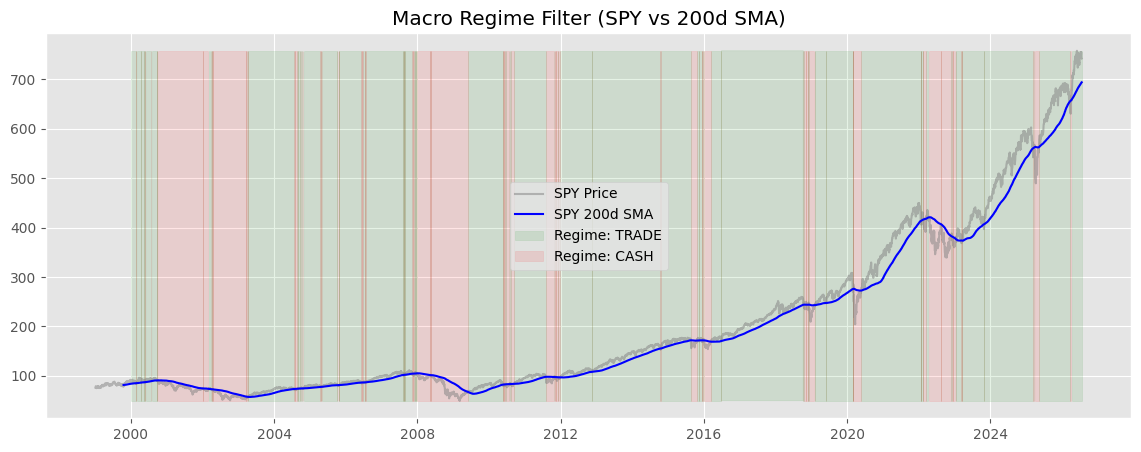

In [ ]:
# 16. Regime-Based Filter: The "Market Traffic Light"
# We'll use SPY as a proxy for the 'Macro Environment'
# Rules: 
# 1. GREEN: SPY > 200-day SMA (General Uptrend)
# 2. YELLOW/RED: SPY < 200-day SMA (Risk-off / Choppy)

import yfinance as yf

def get_market_regime(prices_df):
    spy = yf.download('SPY', start=prices_df.index.min() - pd.Timedelta(days=365), 
                     end=prices_df.index.max(), auto_adjust=True)
    if isinstance(spy.columns, pd.MultiIndex):
        spy_c = spy['Close']['SPY']
    else:
        spy_c = spy['Close']
    
    spy_sma200 = spy_c.rolling(200).mean()
    
    # Identify Regime: 1 for Trade, 0 for Cash
    regime = (spy_c > spy_sma200).astype(int)
    
    # Filter to match our prices index
    regime = regime.reindex(prices_df.index).ffill().fillna(0)
    return regime, spy_c, spy_sma200

market_regime, spy_c, spy_sma = get_market_regime(prices)

# Visualize the Regime
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(spy_c, color='gray', alpha=0.5, label='SPY Price')
ax.plot(spy_sma, color='blue', label='SPY 200d SMA')
ax.fill_between(market_regime.index, spy_c.min(), spy_c.max(), 
                where=(market_regime == 1), color='green', alpha=0.1, label='Regime: TRADE')
ax.fill_between(market_regime.index, spy_c.min(), spy_c.max(), 
                where=(market_regime == 0), color='red', alpha=0.1, label='Regime: CASH')
plt.title("Macro Regime Filter (SPY vs 200d SMA)")
plt.legend()
plt.show()


## 7. Comparison with S&P 500 (SPY)
Finally, we compare the strategy against the industry standard benchmark: SPY.


[*********************100%***********************]  1 of 1 completed


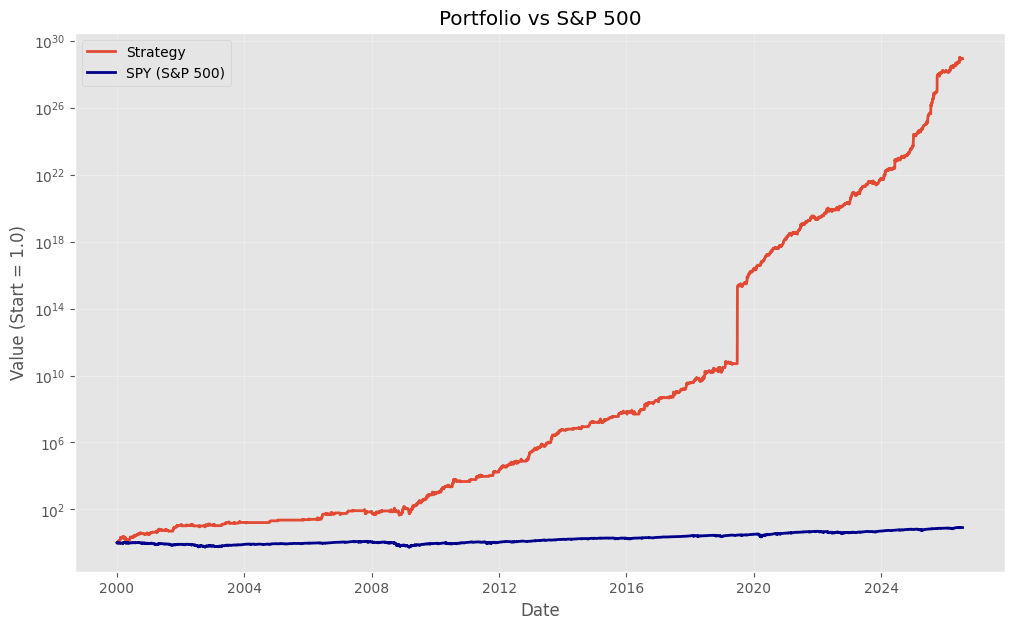

In [ ]:
import yfinance as yf

def compare_spy(trades, prices, title="Portfolio vs S&P 500"):
	# 1. Fetch SPY matching the price history date range
	start_date = prices.index.min().strftime('%Y-%m-%d')
	end_date = prices.index.max().strftime('%Y-%m-%d')
	spy_data = yf.download('SPY', start=start_date, end=end_date, auto_adjust=True)
	
	# Handle both MultiIndex and SingleIndex returns from yfinance
	if isinstance(spy_data.columns, pd.MultiIndex):
		spy_prices = spy_data['Close']['SPY']
	else:
		spy_prices = spy_data['Close']
		
	spy_daily_ret = spy_prices.pct_change().fillna(0)
	spy_cum = (1 + spy_daily_ret).cumprod()
	
	# 2. Strategy equity curve (same as before)
	ticker_daily_ret = prices.pct_change().fillna(0)
	active_mask = pd.DataFrame(0, index=prices.index, columns=prices.columns)
	for _, row in trades.iterrows():
		active_mask.loc[row['entry_date']:row['exit_date'], row['ticker']] = 1
	
	active_count = active_mask.sum(axis=1)
	strat_daily_ret = (ticker_daily_ret * active_mask).sum(axis=1) / active_count
	strat_daily_ret = strat_daily_ret.fillna(0)
	strat_cum = (1 + strat_daily_ret).cumprod()
	
	# 3. Synchronize indices for plotting
	combined = pd.DataFrame({
		'Strategy': strat_cum.squeeze(),
		'SPY': spy_cum.squeeze()
	}).ffill()
	
	# 4. Plot
	plt.figure(figsize=(12, 7))
	plt.plot(combined['Strategy'], label='Strategy', linewidth=2)
	plt.plot(combined['SPY'], label='SPY (S&P 500)', linewidth=2, color='darkblue')
	
	plt.yscale('log')
	plt.title(title)
	plt.xlabel('Date')
	plt.ylabel('Value (Start = 1.0)')
	plt.legend()
	plt.grid(True, alpha=0.3)
	plt.show()

# Run for best params
best_params_trades = simulate_momentum(prices, volume, D1=5, P1=0.15, D2=10)
compare_spy(best_params_trades, prices)


Running 3D Grid Search...

Best Parameters Found:
D1           5.000000
P1           0.200000
D2          10.000000
Return       0.015519
WinRate      0.413551
Count      856.000000
Name: 14, dtype: float64


[*********************100%***********************]  1 of 1 completed


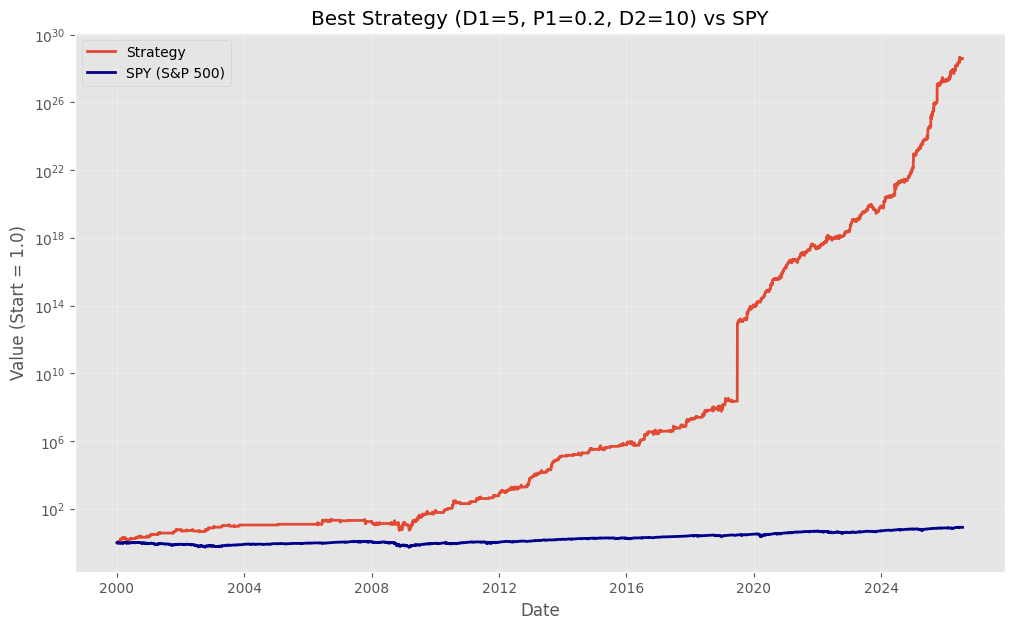

In [ ]:
# 8. Comprehensive 3D Grid Search: D1, P1, D2
# We'll test a few values of D2 as well to find the optimal window
results_3d = []
d1_vals = [3, 5, 8]
p1_vals = [0.10, 0.15, 0.20]
d2_vals = [5, 10, 15]

print("Running 3D Grid Search...")
for d2 in d2_vals:
	for d1 in d1_vals:
		for p1 in p1_vals:
			trades = simulate_momentum(prices, volume, D1=d1, P1=p1, D2=d2)
			if not trades.empty:
				ret = trades['return'].mean()
				win_rate = (trades['return'] > 0).mean()
				results_3d.append({'D1': d1, 'P1': p1, 'D2': d2, 'Return': ret, 'WinRate': win_rate, 'Count': len(trades)})

df_3d = pd.DataFrame(results_3d)
best_3d = df_3d.sort_values('Return', ascending=False).iloc[0]
print("\nBest Parameters Found:")
print(best_3d)

# Plot the absolute best against SPY
best_trades = simulate_momentum(prices, volume, D1=int(best_3d['D1']), P1=best_3d['P1'], D2=int(best_3d['D2']))
compare_spy(best_trades, prices, title=f"Best Strategy (D1={int(best_3d['D1'])}, P1={best_3d['P1']}, D2={int(best_3d['D2'])}) vs SPY")


## 9. Debugging & Logic Step-Through
The $10^{30}$ return suggests a compounding issue or extreme outliers in data. 
We'll take a single ticker, fix the parameters to $D1=20, P1=10\%, D2=10$, and visualize exactly when and why signals are generated.


Top 10 highest return trades:


,ticker,entry_date,exit_date,return,max_drawdown
1610,MARK,2020-04-29,2020-05-13,3.018476,0.000000
1402,IDAI,2024-12-30,2025-01-15,2.741666,-0.525000
1324,FOBIF,2025-10-03,2025-10-17,1.800000,0.000000
1295,FOBIF,2020-11-30,2020-12-14,1.631579,0.000000
1934,SOUN,2023-01-26,2023-02-09,1.580645,0.000000
1944,SOUN,2024-02-09,2024-02-26,1.544248,-0.002212
2334,UIS,2008-12-19,2009-01-06,1.407407,-0.018519
2141,TRCK,2012-12-07,2012-12-21,1.333333,0.000000
1666,NEXCF,2020-06-23,2020-07-08,1.306533,0.000000
32,ALFIQ,2021-06-15,2021-06-29,1.281205,-0.117647



Stepping through signals for: MARK


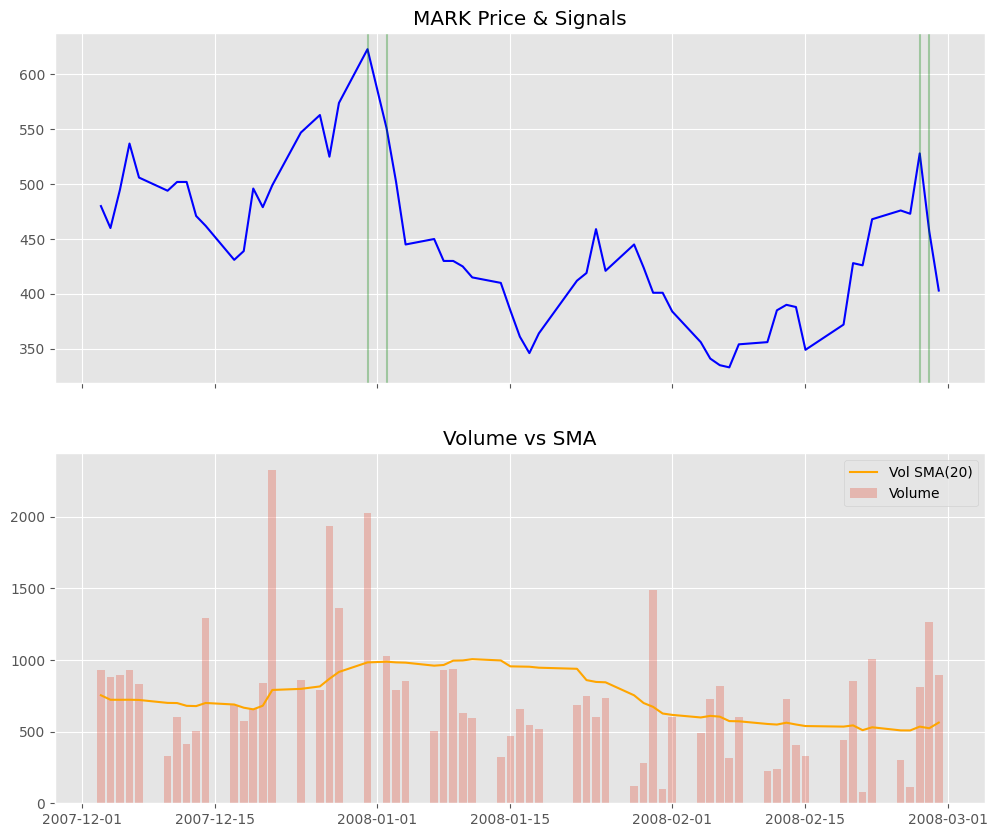

In [ ]:
# 1. Inspect Outliers
# Let's see if we have any trades with physically impossible returns
test_trades = simulate_momentum(prices, volume, D1=20, P1=0.10, D2=10)
print("Top 10 highest return trades:")
display(test_trades.sort_values('return', ascending=False).head(10))

# 2. Logic Step-Through for a Single Ticker (e.g., TSLA or NVDA if present)
target_ticker = test_trades.sort_values('return', ascending=False).iloc[0]['ticker']
print(f"\nStepping through signals for: {target_ticker}")

def debug_ticker_logic(ticker, prices, volume, D1=20, P1=0.10, D2=10):
	p = prices[ticker]
	v = volume[ticker]
	
	# Signal Components
	ret_d1 = p.pct_change(D1)
	v_sma = v.rolling(D1).mean()
	
	sig_price = ret_d1 >= P1
	sig_vol = v > v_sma
	signals = sig_price & sig_vol
	
	# Plot results for a specific window
	# Find first signal date
	first_sig = signals[signals].index[0]
	start_plot = first_sig - pd.Timedelta(days=30)
	end_plot = first_sig + pd.Timedelta(days=60)
	
	fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)
	
	ax1.plot(p[start_plot:end_plot], label='Price', color='blue')
	ax1.set_title(f"{ticker} Price & Signals")
	
	# Highlight signals
	sig_dates = signals[start_plot:end_plot]
	sig_dates = sig_dates[sig_dates].index
	for sd in sig_dates:
		ax1.axvline(sd, color='green', alpha=0.3, label='Signal' if sd == sig_dates[0] else "")
		
	ax2.bar(v[start_plot:end_plot].index, v[start_plot:end_plot], alpha=0.3, label='Volume')
	ax2.plot(v_sma[start_plot:end_plot], color='orange', label=f'Vol SMA({D1})')
	ax2.set_title("Volume vs SMA")
	
	plt.legend()
	plt.show()

debug_ticker_logic(target_ticker, prices, volume)


Step-through logic for MARK (Simplified Params):
2020-03-30: Price=3.88 | 20d_Ret=-31.87% (Needs 10%) | Vol=1,130,759 (Needs > 691,327) | ---
2020-03-31: Price=3.93 | 20d_Ret=-19.49% (Needs 10%) | Vol=763,006 (Needs > 713,476) | ---
2020-04-01: Price=3.82 | 20d_Ret=-20.60% (Needs 10%) | Vol=1,160,381 (Needs > 763,410) | ---
2020-04-02: Price=3.72 | 20d_Ret=-14.85% (Needs 10%) | Vol=550,742 (Needs > 782,269) | ---
2020-04-03: Price=3.80 | 20d_Ret=-0.84% (Needs 10%) | Vol=597,401 (Needs > 800,824) | ---
2020-04-06: Price=4.15 | 20d_Ret=5.83% (Needs 10%) | Vol=764,191 (Needs > 823,382) | ---
2020-04-07: Price=4.06 | 20d_Ret=1.60% (Needs 10%) | Vol=745,933 (Needs > 831,252) | ---
2020-04-08: Price=4.05 | 20d_Ret=-10.00% (Needs 10%) | Vol=538,045 (Needs > 798,931) | ---
2020-04-09: Price=3.95 | 20d_Ret=23.82% (Needs 10%) | Vol=382,646 (Needs > 797,065) | ---
2020-04-13: Price=3.83 | 20d_Ret=6.31% (Needs 10%) | Vol=550,114 (Needs > 773,222) | ---
2020-04-14: Price=4.12 | 20d_Ret=39.66% (Need

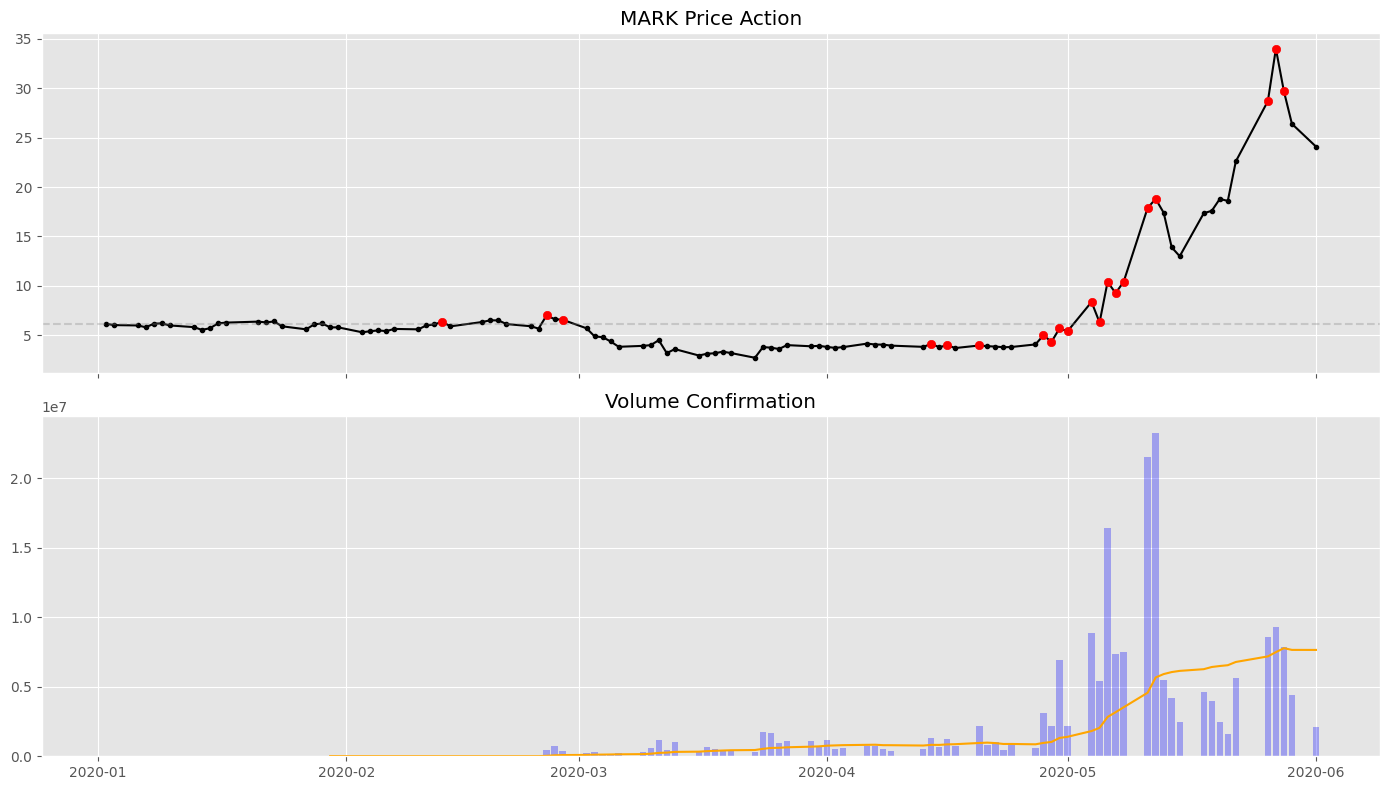

In [ ]:
# 10. Manual Logic Step-Through for MARK
# We'll use the user's requested simplified parameters
# D1=20 (Lookback), P1=10% (Threshold), D2=10 (Holding)

target = 'MARK'
p = prices[target].loc['2020-01-01':'2020-06-01']
v = volume[target].loc['2020-01-01':'2020-06-01']

# Calculate components
ret_20d = p.pct_change(20)
v_sma_20d = v.rolling(20).mean()

# Identify manual signal point (visualizing around April 2020)
signal_points = (ret_20d >= 0.10) & (v > v_sma_20d)

# Detailed Print for a few dates
print(f"Step-through logic for {target} (Simplified Params):")
sample_range = p.index[60:85] # Around the signal
for d in sample_range:
	r = ret_20d[d]
	vol = v[d]
	v_sma = v_sma_20d[d]
	is_sig = signal_points[d]
	
	status = "TRIGGER" if is_sig else "---"
	print(f"{d.date()}: Price={p[d]:.2f} | 20d_Ret={r:.2%} (Needs 10%) | Vol={vol:,.0f} (Needs > {v_sma:,.0f}) | {status}")

# Visualize
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax1.plot(p, label='Price', color='black', marker='.')
ax1.axhline(p.iloc[0], color='gray', linestyle='--', alpha=0.3)
ax1.set_title(f"{target} Price Action")

# Highlight triggers
triggers = p[signal_points]
ax1.scatter(triggers.index, triggers.values, color='red', label='Signals', zorder=5)

ax2.bar(v.index, v, color='blue', alpha=0.3, label='Daily Volume')
ax2.plot(v_sma_20d, color='orange', label='20d Vol SMA')
ax2.set_title("Volume Confirmation")

plt.tight_layout()
plt.show()


[*********************100%***********************]  1 of 1 completed


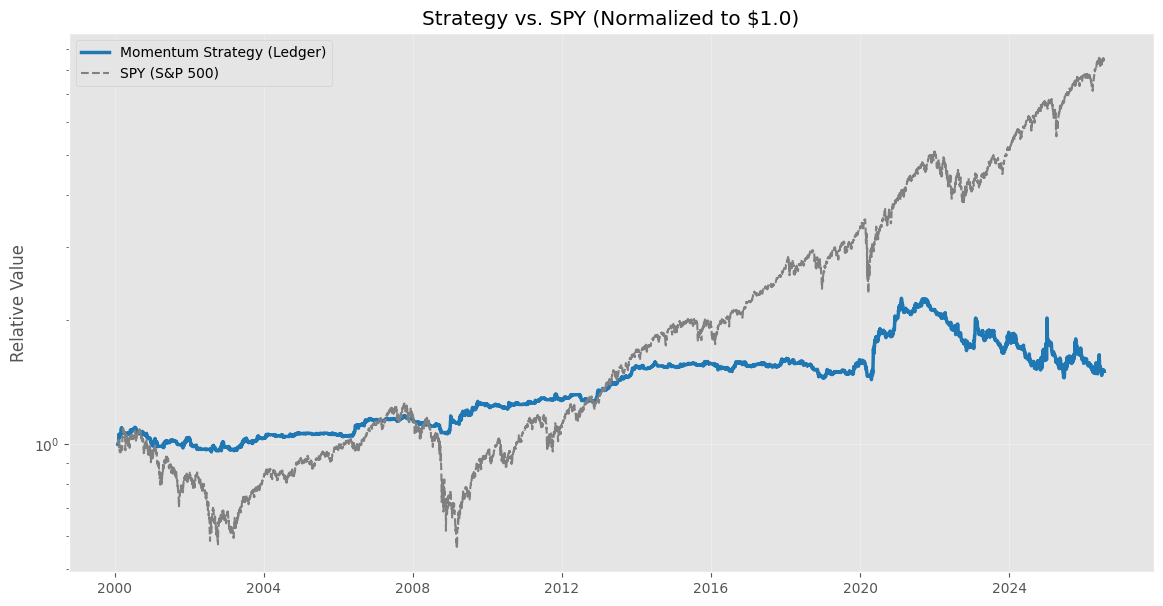


Logic Audit: Top 10 Most Profitable Trades in Ledger


,ticker,entry_date,exit_date,return
1296,MARK,2020-04-28,2020-05-12,2.760000
2349,IDAI,2024-12-30,2025-01-15,2.741666
1439,FOBIF,2020-11-25,2020-12-10,1.847818
2542,FOBIF,2025-10-03,2025-10-17,1.800000
2129,SOUN,2024-02-09,2024-02-26,1.544248
441,UIS,2008-12-19,2009-01-06,1.407407
662,TRCK,2012-12-07,2012-12-21,1.333333
1350,NEXCF,2020-06-22,2020-07-07,1.324324
1567,ALFIQ,2021-06-15,2021-06-29,1.281205
2476,FOBIF,2025-07-16,2025-07-30,1.272727



Audit Note: The top trade was MARK from 2020-04-28 to 2020-05-12.
Return: 276.00%


In [ ]:
# 12. Sanity Check: Top Trades & Relative Performance vs SPY
# Normalized to $1.0 start for easier comparison

# 1. Prepare normalized performance data
initial_val = ledger_hist.iloc[0]['total_nav']
ledger_normalized = ledger_hist['total_nav'] / initial_val

# 2. Fetch/Normalize SPY for the same period
spy_ticker = yf.download('SPY', start=ledger_hist['date'].min(), end=ledger_hist['date'].max(), auto_adjust=True)
if isinstance(spy_ticker.columns, pd.MultiIndex):
    spy_c = spy_ticker['Close']['SPY']
else:
    spy_c = spy_ticker['Close']

spy_normalized = spy_c / spy_c.iloc[0]

# 3. Plot Comparison
plt.figure(figsize=(14, 7))
plt.plot(ledger_hist['date'], ledger_normalized, label='Momentum Strategy (Ledger)', linewidth=2.5, color='tab:blue')
plt.plot(spy_normalized.index, spy_normalized, label='SPY (S&P 500)', linewidth=1.5, color='gray', linestyle='--')

plt.title("Strategy vs. SPY (Normalized to $1.0)")
plt.ylabel("Relative Value")
plt.yscale('log') # Log scale for growth comparison
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# 4. Display Top 10 Trades for Logic Audit
print("\nLogic Audit: Top 10 Most Profitable Trades in Ledger")
top_trades = ledger_trades.sort_values('return', ascending=False).head(10)
display(top_trades)

# Check one specifically (e.g., the top one) to see if it occurred during a known rally
best_t = top_trades.iloc[0]
print(f"\nAudit Note: The top trade was {best_t['ticker']} from {best_t['entry_date'].date()} to {best_t['exit_date'].date()}.")
print(f"Return: {best_t['return']:.2%}")


Audit Window: 2019-12-02 to 2020-02-28
Tickers with >50% daily move in this window: 1
Tickers with >10% missing data in this window: 15


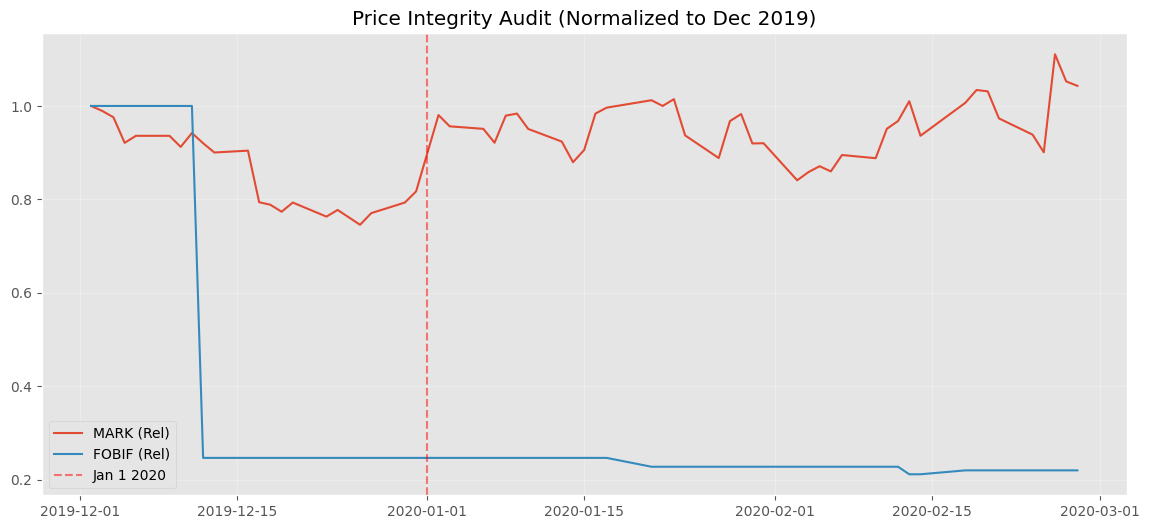


Ticker with most Zero-Volume days:
ticker
AI       61
ALFIQ    61
ASNS     61
BBAI     61
S        61
dtype: int64


In [ ]:
# 13. Data Integrity Audit: 2020 Discordance Check (REVISED)
# Analyzing price action around Jan 2020 for anomalies

start_2020_date = pd.to_datetime('2019-12-01')
end_2020_date = pd.to_datetime('2020-03-01')

# Ensure we use valid indices
actual_start = prices.index[prices.index >= start_2020_date][0]
actual_end = prices.index[prices.index <= end_2020_date][-1]

prices_2020 = prices.loc[actual_start:actual_end]

# 1. Check for extreme single-day returns (> 50% or < -50%)
daily_rets = prices_2020.pct_change()
outliers = (daily_rets.abs() > 0.50).sum()
outlier_tickers = outliers[outliers > 0].index.tolist()

print(f"Audit Window: {actual_start.date()} to {actual_end.date()}")
print(f"Tickers with >50% daily move in this window: {len(outlier_tickers)}")

# 2. Check for missing values (NaNs) which might cause discontinuities if filled
nans_pct = prices.loc[actual_start:actual_end].isna().mean()
high_nan_tickers = nans_pct[nans_pct > 0.1].index.tolist()
print(f"Tickers with >10% missing data in this window: {len(high_nan_tickers)}")

# 3. Visualize a sample of 'Top Trades' and 'Outliers'
# We focus on MARK since it was a top performer
audit_list = ['MARK'] + outlier_tickers[:2]
audit_list = list(set([t for t in audit_list if t in prices.columns]))

plt.figure(figsize=(14, 6))
for t in audit_list:
    # Normalize to 1.0 at start of audit for visualization
    p_series = prices.loc[actual_start:actual_end, t].ffill()
    norm_p = p_series / p_series.iloc[0]
    plt.plot(norm_p, label=f"{t} (Rel)")

plt.title("Price Integrity Audit (Normalized to Dec 2019)")
plt.axvline(pd.to_datetime('2020-01-01'), color='red', linestyle='--', alpha=0.5, label='Jan 1 2020')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 4. Check for ticker-wide gaps (Volume = 0 on trading days)
zero_vol_counts = (volume.loc[actual_start:actual_end] == 0).sum()
print("\nTicker with most Zero-Volume days:")
print(zero_vol_counts.sort_values(ascending=False).head(5))


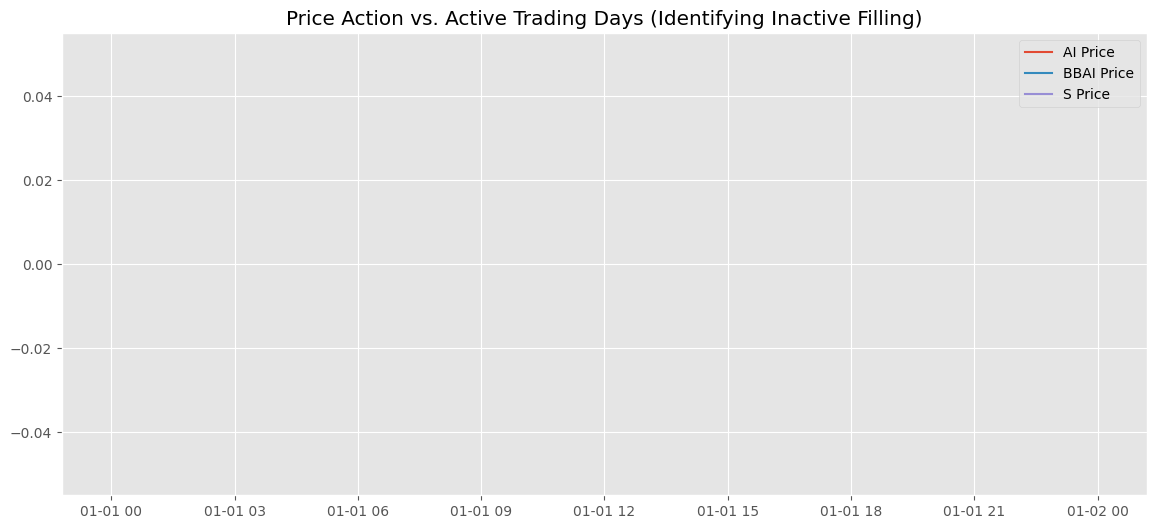

Tickers with ZERO volume on Jan 2, 2020: 17 out of 53


In [ ]:
# 14. Deep Dive: The "Zero-Volume Jump" Hypothesis
# We suspect tickers like 'AI' or 'BBAI' are creating artifacts

suspicious = ['AI', 'BBAI', 'S']
plt.figure(figsize=(14, 6))

for s in suspicious:
    if s in prices.columns:
        p_subset = prices.loc['2019-10-01':'2020-06-01', s]
        v_subset = volume.loc['2019-10-01':'2020-06-01', s]
        
        plt.plot(p_subset.index, p_subset, label=f"{s} Price")
        # Mark where volume > 0
        trading = v_subset[v_subset > 0].index
        if len(trading) > 0:
            plt.scatter(trading, p_subset[trading], color='black', s=5, alpha=0.3, label=f"{s} Trading Days" if s == suspicious[0] else "")

plt.title("Price Action vs. Active Trading Days (Identifying Inactive Filling)")
plt.legend()
plt.show()

# Verification: How many tickers in the universe have zero volume on 2020-01-02?
non_trading_start = (volume.loc['2020-01-02'] == 0).sum()
print(f"Tickers with ZERO volume on Jan 2, 2020: {non_trading_start} out of {len(universe)}")
